# Sprint 4 — Exploratory Data Analysis

## Objective

Explore customer interaction patterns, purchasing behavior,
product performance, and revenue trends using the cleaned
e-commerce event dataset.

## Business Questions

1. Which event types are most frequent?
2. How does customer activity change over time?
3. Which products and brands generate the most interactions and purchases?
4. How does customer behavior vary across users?
5. How are purchase revenues distributed across months, products, and brands?

## Analytical Approach

- Descriptive statistics
- Event distribution analysis
- Time-series exploration
- Customer and product segmentation
- Revenue analysis
- Data visualization

## Data Source

Cleaned monthly Parquet files generated during Sprint 3,
containing 20,692,840 customer interaction events.

In [2]:
import pandas as pd 
import pandas as np
import matplotlib.pyplot as plt 
from pathlib import Path 


In [3]:
# Path to the cleaned dataset
clean_data_path = Path("../data/processed/ecommerce_events_clean")

# List available Parquet files
parquet_files = sorted(clean_data_path.glob("*.parquet"))

print("Parquet files found:", len(parquet_files))

for file in parquet_files:
    print(file.name)

Parquet files found: 5
2019-Dec_clean.parquet
2019-Nov_clean.parquet
2019-Oct_clean.parquet
2020-Feb_clean.parquet
2020-Jan_clean.parquet


In [6]:
# Sort Parquet files chronologically
parquet_files = sorted(
    parquet_files,
    key=lambda file: pd.to_datetime(
        file.name[:8],
        format="%Y-%b"
    )
)

# Verify chronological order
for file in parquet_files:
    print(file.name)

2019-Oct_clean.parquet
2019-Nov_clean.parquet
2019-Dec_clean.parquet
2020-Jan_clean.parquet
2020-Feb_clean.parquet


In [7]:
# Count event types across all months
event_counts = pd.Series(dtype="int64")

for file in parquet_files:
    df = pd.read_parquet(
        file,
        columns=["event_type"]
    )

    monthly_counts = df["event_type"].value_counts()

    event_counts = event_counts.add(
        monthly_counts,
        fill_value=0
    )

event_counts = event_counts.astype("int64")

print(event_counts)
print("\nTotal events:", event_counts.sum())

event_type
cart                5768333
purchase            1287007
remove_from_cart    3979679
view                9657821
dtype: int64

Total events: 20692840


The analysis shows that product views represent the largest share of customer interactions. However, the high number of remove_from_cart events is particularly interesting because it may indicate changes in customers' purchase intentions. Further analysis is needed to understand whether these actions are associated with customers leaving the purchase process without completing a transaction.

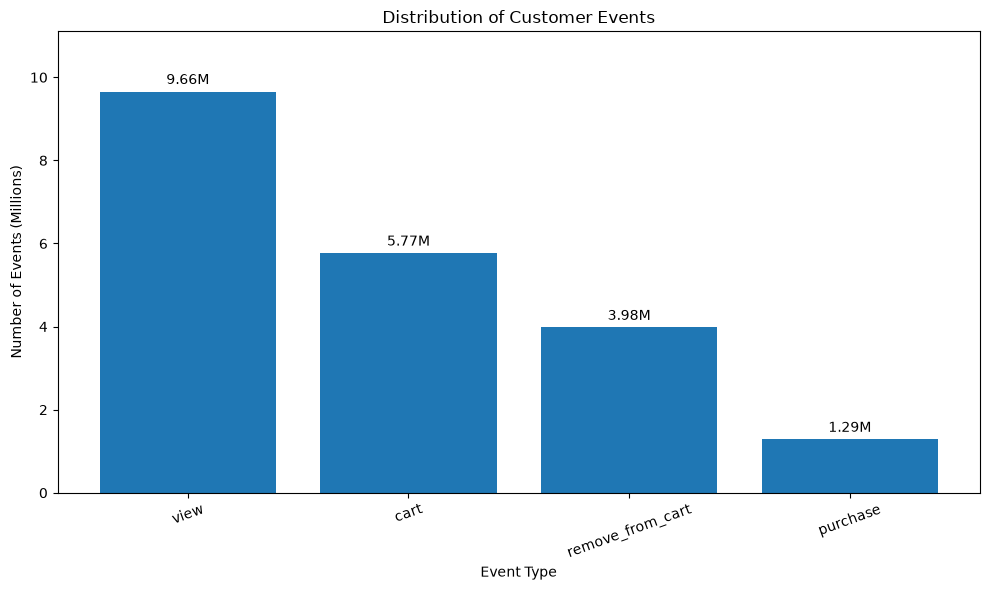

In [12]:
# Sort event counts
event_counts_sorted = event_counts.sort_values(
    ascending=False
)

# Convert event counts to millions
event_counts_millions = event_counts_sorted / 1_000_000

# Create chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    event_counts_millions.index,
    event_counts_millions.values
)

# Add value labels
plt.bar_label(
    bars,
    fmt="%.2fM",
    padding=3
)

plt.title("Distribution of Customer Events")
plt.xlabel("Event Type")
plt.ylabel("Number of Events (Millions)")

plt.xticks(rotation=20)
plt.ylim(0, event_counts_millions.max() * 1.15)

plt.tight_layout()
plt.savefig(
    "../images/event_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



In [13]:
# Calculate monthly event distribution
monthly_event_counts = []

for file in parquet_files:

    df = pd.read_parquet(
        file,
        columns=["event_type"]
    )

    month = file.name[:8]

    counts = df["event_type"].value_counts()

    for event_type, count in counts.items():
        monthly_event_counts.append({
            "month": month,
            "event_type": event_type,
            "event_count": count
        })

monthly_events = pd.DataFrame(monthly_event_counts)

monthly_events

,month,event_type,event_count
0,2019-Oct,view,1862164
1,2019-Oct,cart,1232385
2,2019-Oct,remove_from_cart,762110
3,2019-Oct,purchase,245624
4,2019-Nov,view,2076132
5,2019-Nov,cart,1311807
6,2019-Nov,remove_from_cart,925481
7,2019-Nov,purchase,322417
8,2019-Dec,view,1728331
9,2019-Dec,cart,927124


In [14]:
# Convert monthly event data into a comparison table
monthly_events_pivot = monthly_events.pivot(
    index="month",
    columns="event_type",
    values="event_count"
)

# Preserve chronological order
month_order = [file.name[:8] for file in parquet_files]

monthly_events_pivot = monthly_events_pivot.reindex(
    month_order
)

# Calculate total events per month
monthly_events_pivot["total_events"] = (
    monthly_events_pivot.sum(axis=1)
)

monthly_events_pivot

event_type,cart,purchase,remove_from_cart,view,total_events
month,,,,,
2019-Oct,1232385,245624,762110,1862164,4102283
2019-Nov,1311807,322417,925481,2076132,4635837
2019-Dec,927124,213176,664655,1728331,3533286
2020-Jan,1148323,263797,815024,2037608,4264752
2020-Feb,1148694,241993,812409,1953586,4156682


In [15]:
# Calculate month-over-month percentage changes
monthly_growth = monthly_events_pivot.pct_change() * 100

# Round results to two decimal places
monthly_growth = monthly_growth.round(2)

monthly_growth

event_type,cart,purchase,remove_from_cart,view,total_events
month,,,,,
2019-Oct,NaN,NaN,NaN,NaN,NaN
2019-Nov,6.44,31.26,21.44,11.49,13.01
2019-Dec,-29.32,-33.88,-28.18,-16.75,-23.78
2020-Jan,23.86,23.75,22.62,17.89,20.70
2020-Feb,0.03,-8.27,-0.32,-4.12,-2.53
